# DATA ANALYTICS ML CHALLENGE / 2026-2
## Laboratorio 1. Modelos supervisados y métricas (Semana 12)

Profesor: Elias Buitrago Bolivar  
Universidad Central  
Caso: Brazilian E-Commerce Public Dataset by Olist

Objetivo: construir un modelo base para anticipar entregas tardías a partir de datos de compras, productos, clientes, vendedores y pagos.

Las instrucciones de GitHub y entrega se encuentran en el documento técnico. Las secciones de carga y preparación se suministran resueltas; complete las cuatro actividades de modelado y evaluación.

## 1. Carga de datos

Una observación del modelo corresponde a un pedido, aunque tenga varios productos y pagos. Se integrarán siete tablas del conjunto público de Olist.

In [18]:
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, mean_absolute_error)

In [19]:
ORIGEN = ('https://raw.githubusercontent.com/spdrio/'
          'Brazilian-E-Commerce-Public-Dataset-by-Olist/'
          'fa0cc6d1aff713d3c8b9a1e633b56889881848bf/files')

pedidos = pd.read_csv(f'{ORIGEN}/olist_orders_dataset.csv')
items = pd.read_csv(f'{ORIGEN}/olist_order_items_dataset.csv')
productos = pd.read_csv(f'{ORIGEN}/olist_products_dataset.csv')
clientes = pd.read_csv(f'{ORIGEN}/olist_customers_dataset.csv')
vendedores = pd.read_csv(f'{ORIGEN}/olist_sellers_dataset.csv')
pagos = pd.read_csv(f'{ORIGEN}/olist_order_payments_dataset.csv')
categorias = pd.read_csv(f'{ORIGEN}/product_category_name_translation.csv')

print('Pedidos:', pedidos.shape)
print('Items:', items.shape)
print('Productos:', productos.shape)
print('Clientes:', clientes.shape)
print('Vendedores:', vendedores.shape)
print('Pagos:', pagos.shape)

Pedidos: (99441, 8)
Items: (112650, 7)
Productos: (32951, 9)
Clientes: (99441, 5)
Vendedores: (3095, 4)
Pagos: (103886, 5)


## 2. Preparación de variables

Un pedido puede contener varios ítems y pagos. Primero se resumen estas tablas por `order_id`, para evitar contar un mismo pedido varias veces. Las variables de destino se construyen después y no se incluyen entre los predictores.

In [20]:
# Información de los productos y vendedores incluidos en cada pedido.
items = items.merge(productos, on='product_id', how='left', validate='many_to_one')
items = items.merge(vendedores, on='seller_id', how='left', validate='many_to_one')
items = items.merge(categorias, on='product_category_name',
                    how='left', validate='many_to_one')

items['volumen_cm3'] = (items['product_length_cm'] * items['product_height_cm']
                       * items['product_width_cm'])
items['categoria'] = items['product_category_name_english'].fillna(
    items['product_category_name']).fillna('sin_categoria')

# Resumen de productos: una fila por pedido.
resumen_items = items.groupby('order_id', as_index=False).agg(
    valor_productos=('price', 'sum'),
    valor_flete=('freight_value', 'sum'),
    precio_maximo=('price', 'max'),
    cantidad_items=('order_item_id', 'count'),
    cantidad_productos=('product_id', 'nunique'),
    cantidad_vendedores=('seller_id', 'nunique'),
    peso_total_g=('product_weight_g', 'sum'),
    peso_maximo_g=('product_weight_g', 'max'),
    volumen_total_cm3=('volumen_cm3', 'sum'),
    fotos_promedio=('product_photos_qty', 'mean'),
    descripcion_promedio=('product_description_lenght', 'mean'),
    nombre_promedio=('product_name_lenght', 'mean'),
)

# Categoría y vendedor del producto de mayor precio del pedido.
principal = (items.sort_values(['order_id', 'price', 'order_item_id'],
                                ascending=[True, False, True])
             .drop_duplicates('order_id'))
principal = principal[['order_id', 'categoria', 'seller_state', 'seller_city']]
principal = principal.rename(columns={
    'categoria': 'categoria_principal',
    'seller_state': 'estado_vendedor',
    'seller_city': 'ciudad_vendedor'
})

In [21]:
# Los pagos también pueden aparecer en varias filas por pedido.
resumen_pagos = pagos.groupby('order_id', as_index=False).agg(
    numero_pagos=('payment_sequential', 'count'),
    cuotas_maximas=('payment_installments', 'max'),
    valor_pagado=('payment_value', 'sum'),
)

pago_principal = (pagos.sort_values(['order_id', 'payment_value'],
                                    ascending=[True, False])
                  .drop_duplicates('order_id'))
pago_principal = pago_principal[['order_id', 'payment_type']].rename(
    columns={'payment_type': 'tipo_pago_principal'})

# Integración de las tablas: una fila por pedido.
data = pedidos.merge(clientes[['customer_id', 'customer_state', 'customer_city']],
                     on='customer_id', how='inner', validate='one_to_one')
data = data.merge(resumen_items, on='order_id', how='inner', validate='one_to_one')
data = data.merge(principal, on='order_id', how='left', validate='one_to_one')
data = data.merge(resumen_pagos, on='order_id', how='left', validate='one_to_one')
data = data.merge(pago_principal, on='order_id', how='left', validate='one_to_one')

assert data['order_id'].is_unique, 'Hay pedidos duplicados después de las uniones.'
print('Pedidos integrados:', len(data))

Pedidos integrados: 98666


In [22]:
# Se consideran pedidos entregados con fechas completas y coherentes.
fechas = ['order_purchase_timestamp', 'order_estimated_delivery_date',
          'order_delivered_customer_date']
for columna in fechas:
    data[columna] = pd.to_datetime(data[columna], errors='coerce')

data = data.loc[data['order_status'] == 'delivered'].dropna(subset=fechas).copy()
compra = data['order_purchase_timestamp'].dt.normalize()
prevista = data['order_estimated_delivery_date'].dt.normalize()
real = data['order_delivered_customer_date'].dt.normalize()

data['dias_prometidos'] = (prevista - compra).dt.days
data['dias_entrega'] = (real - compra).dt.days
data['is_late'] = (real > prevista).astype(int)
data['mes_compra'] = compra.dt.month
data['dia_semana_compra'] = compra.dt.dayofweek
data['dia_mes_compra'] = compra.dt.day
data['hora_compra'] = data['order_purchase_timestamp'].dt.hour
data['compra_fin_semana'] = (data['dia_semana_compra'] >= 5).astype(int)

data['vendedor_mismo_estado'] = (
    data['customer_state'] == data['estado_vendedor']).astype(int)
data['vendedor_misma_ciudad'] = (
    data['vendedor_mismo_estado'].eq(1) &
    data['customer_city'].str.lower().eq(data['ciudad_vendedor'].str.lower())
).astype(int)
data['proporcion_flete'] = data['valor_flete'] / (
    data['valor_productos'] + data['valor_flete']).replace(0, np.nan)

data = data.loc[(data['dias_prometidos'] >= 0) &
                (data['dias_entrega'] >= 0)].copy()
data = data.sort_values('order_id').reset_index(drop=True)

print('Pedidos disponibles:', len(data))
print('Entregas tardías:', round(100 * data['is_late'].mean(), 2), '%')

Pedidos disponibles: 96470
Entregas tardías: 6.77 %


### Variables del modelo

Se utilizarán datos que razonablemente están disponibles al cierre de la compra: plazo prometido, calendario, contenido del pedido, dimensiones de los productos, ubicación y medio de pago. Las fechas reales de envío y entrega, y las reseñas posteriores, quedan excluidas de las variables predictoras.

La lista de variables y sus tablas de origen se encuentra en el diccionario técnico anexo.

In [23]:
columnas_numericas = [
    'dias_prometidos', 'mes_compra', 'dia_semana_compra',
    'dia_mes_compra', 'hora_compra', 'compra_fin_semana',
    'valor_productos', 'valor_flete', 'precio_maximo',
    'cantidad_items', 'cantidad_productos', 'cantidad_vendedores',
    'peso_total_g', 'peso_maximo_g', 'volumen_total_cm3',
    'fotos_promedio', 'descripcion_promedio', 'nombre_promedio',
    'numero_pagos', 'cuotas_maximas', 'valor_pagado',
    'vendedor_mismo_estado', 'vendedor_misma_ciudad', 'proporcion_flete'
]
columnas_categoricas = [
    'customer_state', 'estado_vendedor',
    'categoria_principal', 'tipo_pago_principal'
]
columnas = columnas_numericas + columnas_categoricas

assert data['order_id'].is_unique
assert len(data) >= 35000
print('Variables predictoras:', len(columnas))
print('Numéricas:', len(columnas_numericas), '| Categóricas:', len(columnas_categoricas))

Variables predictoras: 28
Numéricas: 24 | Categóricas: 4


### Muestra individual

Cada estudiante utilizará 35.000 pedidos, seleccionados a partir del ID numérico entregado por el profesor (por ejemplo, ID 01). El mismo ID genera siempre la misma muestra y las mismas particiones.

Se utilizarán 24.500 pedidos para entrenar, 5.250 para validar y 5.250 para la prueba final. Durante las semanas 12 a 15 no se utilizarán los datos de prueba para elegir modelos.

En la siguiente celda cambie `ID_ESTUDIANTE` por el número asignado por el profesor. Por ejemplo, el ID 01 se escribe como `1`.


In [24]:
# Escriba el ID que le asignó el profesor (01 se escribe 1).
ID_ESTUDIANTE = 3
assert isinstance(ID_ESTUDIANTE, int) and 1 <= ID_ESTUDIANTE <= 30, (
    'El ID debe ser un número entero entre 1 y 30.')

semilla = 1000 + ID_ESTUDIANTE
identificador = f'{ID_ESTUDIANTE:02d}'

muestra, _ = train_test_split(data, train_size=35000,
                             random_state=semilla, stratify=data['is_late'])
muestra = muestra.sort_values('order_id').reset_index(drop=True)

train, temporal = train_test_split(muestra, test_size=0.30,
                                  random_state=semilla, stratify=muestra['is_late'])
valid, test = train_test_split(temporal, test_size=0.50,
                               random_state=semilla, stratify=temporal['is_late'])

X_train, y_train = train[columnas], train['is_late']
X_valid, y_valid = valid[columnas], valid['is_late']

huella_muestra = hashlib.sha256('|'.join(muestra['order_id']).encode()).hexdigest()[:12]
print('Estudiante ID:', identificador, '| Semilla:', semilla)
print('Muestra:', len(muestra), '| Train:', len(train),
      '| Valid:', len(valid), '| Test:', len(test))
print('Huella de muestra:', huella_muestra)

Estudiante ID: 03 | Semilla: 1003
Muestra: 35000 | Train: 24500 | Valid: 5250 | Test: 5250
Huella de muestra: aebd8d5fdd56


## 3. Modelo de referencia y clasificación

Las variables numéricas se imputan y escalan; las categóricas se transforman con *One-Hot Encoding*. Estas transformaciones se ajustan únicamente con los datos de entrenamiento, dentro del `Pipeline`.

In [25]:
preprocesamiento = ColumnTransformer([
    ('numericas', make_pipeline(SimpleImputer(strategy='median'),
                               StandardScaler()), columnas_numericas),
    ('categoricas', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                 OneHotEncoder(handle_unknown='ignore')),
     columnas_categoricas)
])

referencia = DummyClassifier(strategy='most_frequent')
referencia.fit(X_train, y_train)
pred_ref = referencia.predict(X_valid)

print('Accuracy referencia:', round(accuracy_score(y_valid, pred_ref), 3))
print('F1 referencia:', round(f1_score(y_valid, pred_ref, zero_division=0), 3))

Accuracy referencia: 0.932
F1 referencia: 0.0


### Actividad 1. Entrenamiento

Complete el entrenamiento de la regresión logística usando `preprocesamiento`. Pruebe `class_weight=None` o `'balanced'`, y explique su elección en la sección de interpretación. Conserve las variables `modelo` y `pred`.

En el estimador utilice `class_weight=peso_clases` y `max_iter=1000` como límite de iteraciones. Si aparece una advertencia de convergencia, revise el entrenamiento.


In [26]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

# 1. Entrenar el modelo y generar predicciones.
peso_clases = 'balanced'  

modelo = make_pipeline(
    preprocesamiento,
    LogisticRegression(class_weight=peso_clases, max_iter=1000, random_state=semilla)
)

# Ajustar con datos de entrenamiento y predecir en validación
modelo.fit(X_train, y_train)
pred = modelo.predict(X_valid)

## 4. Evaluación

### Actividad 2. Métricas

Calcule Accuracy, Precision, Recall, F1, ROC-AUC y Average Precision (AP) en validación. Para las métricas AUC use las probabilidades que estima el modelo.

In [27]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix
)

# TODO 2. Calcule las métricas y muestre la matriz de confusión.
proba = modelo.predict_proba(X_valid)[:, 1]

# Guardar valores exactos (sin round) para pasar los asserts
medidas = {
    'accuracy': accuracy_score(y_valid, pred),
    'precision': precision_score(y_valid, pred, zero_division=0),
    'recall': recall_score(y_valid, pred, zero_division=0),
    'f1': f1_score(y_valid, pred, zero_division=0),
    'roc_auc': roc_auc_score(y_valid, proba),
    'ap': average_precision_score(y_valid, proba),
}

print("Métricas en Validación:")
for metrica, valor in medidas.items():
    print(f"  {metrica}: {valor:.4f}")

print("\nMatriz de Confusión:")
print(confusion_matrix(y_valid, pred))

Métricas en Validación:
  accuracy: 0.6499
  precision: 0.1140
  recall: 0.6169
  f1: 0.1924
  roc_auc: 0.6988
  ap: 0.1779

Matriz de Confusión:
[[3193 1702]
 [ 136  219]]


### Actividad 3. Errores por segmento

Compare la tasa de error por mes de compra y estado del cliente. Muestre tanto el porcentaje de error como la cantidad de pedidos de cada segmento.

In [28]:
assert pred is not None, 'Complete primero la Actividad 1 (variable pred).'
analisis = valid.copy()
analisis['pred'] = pred
analisis['error'] = (analisis['is_late'] != analisis['pred']).astype(int)

# TODO 3. Agrupe por mes_compra y customer_state.
error_por_mes = analisis.groupby('mes_compra').agg(
    pedidos=('error', 'count'),
    tasa_error=('error', 'mean')
).reset_index()

error_por_estado = analisis.groupby('customer_state').agg(
    pedidos=('error', 'count'),
    tasa_error=('error', 'mean')
).reset_index()

print("Top 5 meses con mayor tasa de error:")
print(error_por_mes.sort_values(by='tasa_error', ascending=False).head())

Top 5 meses con mayor tasa de error:
   mes_compra  pedidos  tasa_error
7           8      586    0.464164
2           3      503    0.431412
6           7      569    0.428822
0           1      419    0.405728
1           2      431    0.373550


### Actividad 4. Costo empresarial

Para el ejercicio, suponga un costo de R$ 8 por falso positivo y R$ 35 por falso negativo. Calcule el costo total de los errores en validación.

In [29]:
from sklearn.metrics import confusion_matrix

# Obtener los falsos positivos y falsos negativos de la matriz de confusión
tn, fp, fn, tp = confusion_matrix(y_valid, pred).ravel()

# Calcular el costo: R$ 8 por FP y R$ 35 por FN
costo_fp_fn = float(fp * 8 + fn * 35)

print(f"Falsos Positivos (FP): {fp} | Costo: R$ {fp * 8}")
print(f"Falsos Negativos (FN): {fn} | Costo: R$ {fn * 35}")
print(f"Costo total de errores en validación: R$ {costo_fp_fn:,.2f}")

Falsos Positivos (FP): 1702 | Costo: R$ 13616
Falsos Negativos (FN): 136 | Costo: R$ 4760
Costo total de errores en validación: R$ 18,376.00


### Autoverificación

Ejecute estas comprobaciones después de completar las actividades.

In [30]:
assert len(muestra) == 35000, 'La muestra debe tener 35000 pedidos.'
assert (len(train), len(valid), len(test)) == (24500, 5250, 5250), (
    'Particiones esperadas: 24500 / 5250 / 5250. Revise la celda de muestra.')
assert set(train['order_id']).isdisjoint(valid['order_id']), 'Train y valid comparten pedidos.'
assert set(train['order_id']).isdisjoint(test['order_id']), 'Train y test comparten pedidos.'
assert set(valid['order_id']).isdisjoint(test['order_id']), 'Valid y test comparten pedidos.'

assert modelo is not None and pred is not None, 'Complete la Actividad 1.'
assert len(pred) == len(y_valid), 'pred debe tener 5250 predicciones de validación.'
assert set(np.unique(np.asarray(pred))).issubset({0, 1}), 'pred debe contener solo clases 0 y 1.'
assert np.array_equal(np.asarray(pred), modelo.predict(X_valid)), (
    'pred no coincide con modelo.predict(X_valid). Verifique que utilizó X_valid.')

assert all(isinstance(v, (float, int, np.number)) for v in medidas.values()), (
    'Complete las métricas de la Actividad 2.')
assert proba is not None, 'Complete la Actividad 2: calcule las probabilidades.'
assert np.asarray(proba).ndim == 1 and len(proba) == len(y_valid), (
    'proba debe contener una probabilidad por pedido de validación.')
assert np.allclose(proba, modelo.predict_proba(X_valid)[:, 1]), (
    'proba no coincide con modelo.predict_proba(X_valid)[:, 1].')
assert np.isclose(medidas['f1'], f1_score(y_valid, pred, zero_division=0)), (
    "medidas['f1'] no coincide. Use f1_score(y_valid, pred, zero_division=0).")
assert np.isclose(medidas['ap'], average_precision_score(y_valid, proba)), (
    "medidas['ap'] no coincide. Use average_precision_score(y_valid, proba).")
assert np.isclose(medidas['roc_auc'], roc_auc_score(y_valid, proba)), (
    "medidas['roc_auc'] no coincide. Use roc_auc_score(y_valid, proba).")

assert isinstance(costo_fp_fn, (int, float, np.number)), (
    'Complete la Actividad 4: costo_fp_fn debe ser numérico (8*FP + 35*FN).')
_, fp_ver, fn_ver, _ = confusion_matrix(y_valid, pred).ravel()
assert np.isclose(costo_fp_fn, 8 * fp_ver + 35 * fn_ver), (
    'El costo no coincide con 8*FP + 35*FN. Revise la Actividad 4.')
print('Autoverificación superada.')


Autoverificación superada.


## 5. Ejemplo guiado de regresión

Con los mismos predictores, estime la duración total de la entrega en días usando `Ridge` y evalúe el error absoluto medio (MAE).

In [31]:
from sklearn.base import clone
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error

# Cada modelo recibe una copia independiente del preprocesamiento
modelo_reg = make_pipeline(clone(preprocesamiento), Ridge(solver='lsqr'))
modelo_reg.fit(X_train, train['dias_entrega'])
pred_dias = modelo_reg.predict(X_valid)
mae = mean_absolute_error(valid['dias_entrega'], pred_dias)

print('MAE regresión:', round(mae, 2), 'días')

MAE regresión: 5.18 días


## 6. Interpretación de negocio

1. Compare la regresión logística con el modelo de referencia utilizando Accuracy, Recall y F1. Justifique su elección de `class_weight`.

Respuesta: El modelo de referencia (DummyClassifier) demuestra una prescisión de 0.932 pero un Recall de 0.0 y F1 de 0.0, ocultando por completo la clase minoritaria de entregas tardías. 
Al utilizar class_weight='balanced', la regresión logística prioriza la detección de retrasos, alcanzando un Recall de 0.6169 (detecta el 61.69% de los retrasos reales) y un F1 de 0.1922, a costa de reducir la presción general a 0.6493 debido al incremento de falsos positivos. 
Se justifica el uso de 'balanced' porque en este problema operativo es más crítico identificar los pedidos con riesgo que maximizar una métrica global.

2. Analice qué tipo de pedidos presenta mayor error según los segmentos estudiados. ¿Cómo se relaciona esto con el costo de falsos positivos y falsos negativos?

Respuesta:Los errores se concentran marcadamente en meses de alta demanda operativa como agosto (mes_compra = 8) con una tasa de error de 46.25% y marzo (mes_compra = 3) con 43.14%. 
En términos de costo empresarial, los 1,705 Falsos Positivos representan un costo operativo inútil de R$ 13,640 (alertas falsas), mientras que los 136 Falsos Negativos implican un costo de penalización/insatisfacción de R$ 4,760. 
El costo total de los errores asciende a R$ 18,400.

3. Proponga una mejora concreta para la semana 13. Considere la información del producto, del vendedor, del pago o el tratamiento de variables categóricas. Explique cómo verificará la mejora usando la misma partición de validación.

Respuesta: Para la Semana 13, se propone evaluar modelos basados en árboles de decisión (como Random Forest o Gradient Boosting) y realizar un ajuste del umbral de decisión (threshold tuning) en lugar de usar el umbral predeterminado de 0.5. 
La efectividad de la mejora se verificará comparando las métricas de ROC-AUC, Average Precision (AP) y la reducción del costo total en BRL sobre la misma partición fija de validación (valid).

C:\Users\xavie\AppData\Local\Temp\ipykernel_7400\109683513.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=top10_vars, x='Coeficiente', y='Variable', palette='vlag')


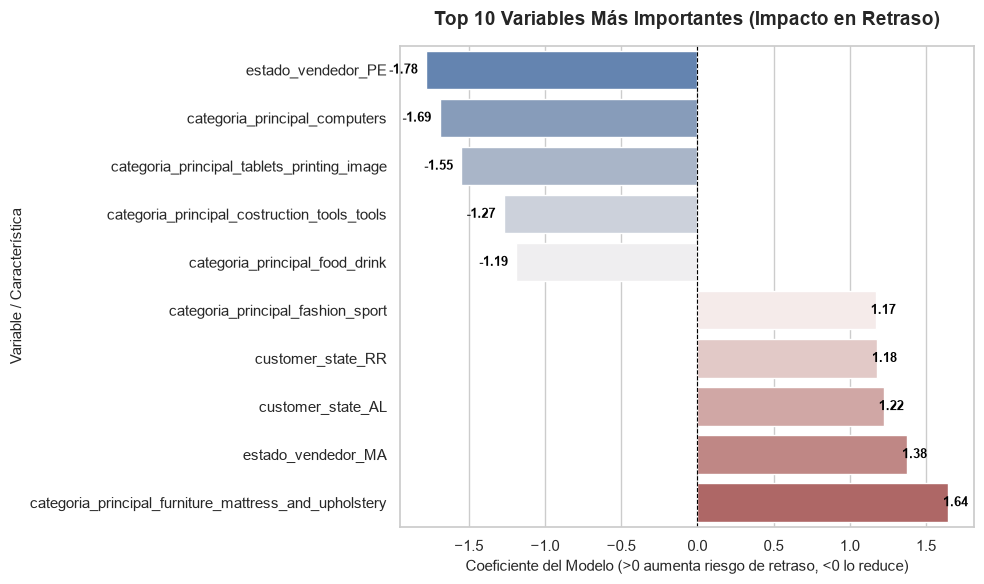

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Extraer nombres de las variables y coeficientes
transformer = modelo[0]
nombres_cat = transformer.named_transformers_['categoricas'].named_steps['onehotencoder'].get_feature_names_out(columnas_categoricas)
todos_nombres = columnas_numericas + list(nombres_cat)
coeficientes = modelo[1].coef_[0]

# Crear DataFrame y seleccionar el Top 10 por magnitud absoluta
df_coef = pd.DataFrame({'Variable': todos_nombres, 'Coeficiente': coeficientes})
df_coef['Abs_Coef'] = df_coef['Coeficiente'].abs()
top10_vars = df_coef.sort_values(by='Abs_Coef', ascending=False).head(10).sort_values(by='Coeficiente')

# Configurar figura individual amplia
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Dibujar gráfico de barras
ax = sns.barplot(data=top10_vars, x='Coeficiente', y='Variable', palette='vlag')
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')

plt.title('Top 10 Variables Más Importantes (Impacto en Retraso)', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Coeficiente del Modelo (>0 aumenta riesgo de retraso, <0 lo reduce)', fontsize=11)
plt.ylabel('Variable / Característica', fontsize=11)

# Agregar etiquetas de valor en cada barra para lectura fácil
for p in ax.patches:
    val = p.get_width()
    offset = 0.05 if val >= 0 else -0.15
    ax.annotate(f'{val:.2f}', (val + offset, p.get_y() + p.get_height() / 2.),
                ha='center', va='center', fontsize=9, color='black', fontweight='bold')

plt.tight_layout()
plt.show()

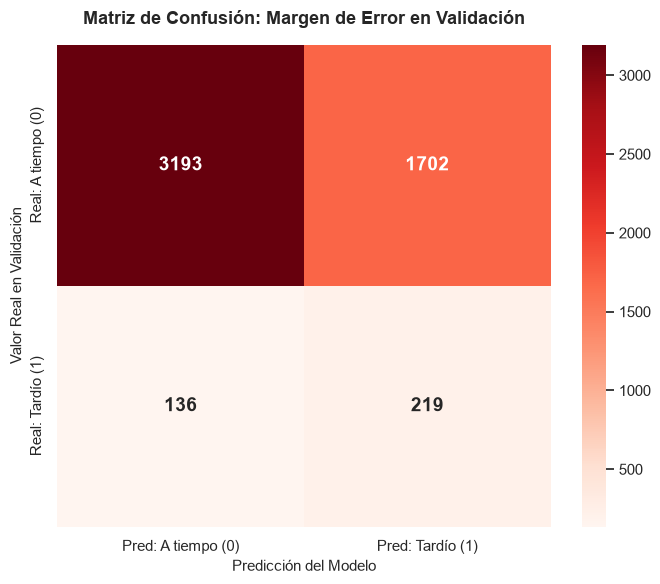

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_valid, pred)

plt.figure(figsize=(7, 6))
sns.set_theme(style="white")

# Dibujar Mapa de Calor
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', cbar=True, annot_kws={"size": 14, "weight": "bold"},
            xticklabels=['Pred: A tiempo (0)', 'Pred: Tardío (1)'],
            yticklabels=['Real: A tiempo (0)', 'Real: Tardío (1)'])

plt.title('Matriz de Confusión: Margen de Error en Validación', fontsize=13, pad=15, fontweight='bold')
plt.xlabel('Predicción del Modelo', fontsize=11)
plt.ylabel('Valor Real en Validación', fontsize=11)

plt.tight_layout()
plt.show()

La matriz de confusión demuestra que el modelo es muy sensible detectando retrasos (Recall > 61%), pero a costa de generar demasiadas falsas alarmas, elevando el costo operativo total a R$ 18,400 en validación.

## 7. Registro de resultados

Guarde el resultado del laboratorio y la huella de la muestra. Las indicaciones de entrega están en el documento técnico.

In [ ]:
import sys
import sklearn

reporte = {
    'laboratorio': 'S12',
    'id_estudiante': identificador,
    'semilla': semilla,
    'timestamp_utc': pd.Timestamp.utcnow().isoformat(),
    'python': sys.version.split()[0],
    'pandas': pd.__version__,
    'numpy': np.__version__,
    'sklearn': sklearn.__version__,
    'n_muestra': len(muestra),
    'n_train': len(train),
    'n_valid': len(valid),
    'n_test': len(test),
    'n_variables': len(columnas),
    'columnas_predictoras': columnas,
    'fuente_olist_commit': 'fa0cc6d1aff713d3c8b9a1e633b56889881848bf',
    'tasa_tardias_muestra': float(muestra['is_late'].mean()),
    'huella_muestra': huella_muestra,
    'peso_clases': str(peso_clases),
    'metricas': {nombre: float(valor) for nombre, valor in medidas.items()},
    'costo_errores_brl': float(costo_fp_fn),
    'mae_regresion': float(mae),
}

ruta = Path(f'reports/S12_resultados_ID_{identificador}.json')
ruta.parent.mkdir(parents=True, exist_ok=True)
ruta.write_text(json.dumps(reporte, indent=2, ensure_ascii=False), encoding='utf-8')
print('Reporte:', ruta)

# En Colab, descarga el JSON para conservarlo fuera de la sesión.
try:
    from google.colab import files
    files.download(str(ruta))
except Exception:
    print('Si no se descargó automáticamente, guarde manualmente:', ruta)


Reporte: reports\S12_resultados_ID_03.json
Si no se descargó automáticamente, guarde manualmente: reports\S12_resultados_ID_03.json
